<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_7_%7C_LESSON_2_Model_Failure_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 7 | LESSON 2: Model Failure Analysis

| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | Statistical modeling, machine learning basics, risk management concepts, model validation techniques, basic econometrics |
|**Keywords** | model risk, regime shifts, structural breaks, CUSUM, change point detection, model governance, backtesting, model validation, statistical process control, early warning systems |

---

## **Introduction**

For the purposes of this lesson, a model failure is like a trusted friend who lies to you at the worst possible moment – and, unfortunately, one that happens far more often than the textbooks suggest. Models are mathematical shadows of reality. They work beautifully until they don't.

A bit more precisely, we say a model has failed when its predictions systematically deviate from observed outcomes in ways that cannot be attributed to normal statistical variation, when its fundamental assumptions no longer hold, or when its deployment creates unintended consequences that invalidate its own premises. It pays to understand that even Nobel Prize-winning models can fail spectacularly (why do you think LTCM collapsed?). This lesson dissects these failures to extract practical wisdom for building more resilient modeling frameworks.

## **1. Early Warning Indicators of Model Breakdown**

### **1.1 The Canaries in the Coal Mine**

Models rarely die instantly. They decay slowly, like a marriage heading for divorce – the warning signs are there if you know where to look. The challenge lies in distinguishing the normal heartbeat of statistical variation from the irregular rhythm that signals impending cardiac arrest.

Consider the systematic deviation of prediction errors from their expected distribution. When a model is healthy, its errors dance around zero in a predictable pattern. But as the underlying world shifts, these errors begin to march in formation – persistent bias emerges, skewness creeps in, and serial correlation patterns appear where none existed before (have you ever wondered why this happens gradually rather than suddenly?). These deviations whisper before they scream.

A bit more precisely, we monitor the evolution of error moments over rolling windows. If $e_t$ represents the prediction error at time $t$, we track:
- **Bias drift**: $\bar{e}_T = \frac{1}{T}\sum_{t=1}^{T}e_t$ moving systematically away from zero
- **Volatility clustering**: $\sigma^2_T = \frac{1}{T-1}\sum_{t=1}^{T}(e_t - \bar{e}_T)^2$ exhibiting persistent increases
- **Skewness emergence**: $S_T = \frac{\frac{1}{T}\sum_{t=1}^{T}(e_t - \bar{e}_T)^3}{(\sigma^2_T)^{3/2}}$ departing from assumed symmetry

Take sentiment analysis models processing financial news. They fail like a foreign correspondent who gradually loses touch with local idioms. The model trained on pre-cryptocurrency financial language stumbles over "DeFi protocols" and "yield farming" – terms that didn't exist in its training corpus. The early warnings manifest as increased uncertainty scores on specific text segments and growing clusters of misclassified examples sharing common linguistic DNA.

### **1.2 When Logic Goes on Holiday**

Note that models can violate fundamental business logic while maintaining superficially acceptable statistical performance. This is perhaps the most insidious form of decay. A credit risk model might generate default probabilities that ignore the term structure – shorter-term probabilities exceeding longer-term ones for identical obligors (does this make economic sense?). Or an options pricing model might create implied volatilities that spell out arbitrage opportunities in neon lights.

It pays to monitor these logical violations systematically. They often emerge at the boundaries of the model's training domain, where extrapolation becomes necessary and assumptions break down. The danger of linear thinking in a nonlinear world becomes acute here, particularly when leverage amplifies small errors into large losses.

## **2. Model Performance Monitoring Using Statistical Process Control**

### **2.1 The Manufacturing Mindset Applied to Finance**

Statistical Process Control treats model monitoring like quality control on a factory floor – which is both illuminating and slightly absurd, given that financial markets bear little resemblance to assembly lines. The core insight remains valuable: establish control limits based on expected performance variability, then sound alarms when observations venture beyond these bounds.

The implementation begins with baseline establishment during stable periods when the model performs reliably. We calculate performance metric statistics – accuracy, precision, recall, or domain-specific measures like Sharpe ratios for trading algorithms. Control limits typically follow the $\mu \pm 3\sigma$ convention, where excursions trigger investigation (but why three standard deviations rather than two or four?).

A bit more precisely, for a performance metric $X_t$ with historical mean $\mu_X$ and standard deviation $\sigma_X$, we define:
- **Upper Control Limit**: $UCL = \mu_X + 3\sigma_X$  
- **Lower Control Limit**: $LCL = \mu_X - 3\sigma_X$
- **Center Line**: $CL = \mu_X$

An alarm triggers when $X_t > UCL$ or $X_t < LCL$.

However, financial markets mock manufacturing analogies. Unlike widget production where defects are independent and identically distributed, financial model errors exhibit clustering, autocorrelation, and regime-dependent behavior. This necessitates EWMA (Exponentially Weighted Moving Average) charts that emphasize recent observations over ancient history. The EWMA statistic evolves as:

$$EWMA_t = \lambda X_t + (1-\lambda)EWMA_{t-1}$$

where $\lambda \in (0,1]$ controls the memory decay rate.

### **2.2 The Curse of Dimensionality in Monitoring**

Models fail along multiple dimensions simultaneously, like a symphony orchestra where several instruments gradually drift out of tune. Monitoring each metric independently misses the subtle interdependencies that signal collective breakdown. The Hotelling $T^2$ statistic provides multivariate surveillance, tracking the joint distribution of multiple model outputs or performance metrics.

Consider monitoring a portfolio optimization model that juggles returns, risk, turnover, and concentration. Each metric might individually appear acceptable while their joint behavior screams danger. The $T^2$ statistic for observation vector $\mathbf{x}_t$ with sample mean $\overline{\mathbf{x}}$ and covariance matrix $\mathbf{S}$ is:

$$T^2_t = (\mathbf{x}_t - \overline{\mathbf{x}})^T \mathbf{S}^{-1} (\mathbf{x}_t - \overline{\mathbf{x}})$$

Values exceeding the critical threshold $T^2_{\alpha,p,n-p}$ suggest multivariate performance deviation. Note that this approach assumes stable covariance structure – an assumption that financial markets violate with gleeful regularity.

## **3. Regime Shifts and Model Adaptation**

### **3.1 When the Rules of the Game Change**

Financial markets undergo regime shifts like a country changing its constitution – fundamental alterations in the data-generating process that render existing models obsolete. These shifts can crawl slowly across decades (like secular interest rate declines) or strike suddenly (like regulatory earthquakes following financial crises).

The challenge resembles distinguishing genuine climate change from weather fluctuations. We need detection methods sensitive enough to identify real shifts quickly but robust enough to ignore temporary market tantrums (how do we calibrate this trade-off optimally?). The identification requires analyzing model residuals and feature relationships for systematic patterns that persist beyond normal variability.

A bit more precisely, we employ structural break tests to identify regime changes. The CUSUM test examines whether the cumulative sum of standardized residuals wanders too far from zero:

$$W_t = \frac{1}{\hat{\sigma}\sqrt{n}} \sum_{i=1}^t \hat{u}_i$$

where $\hat{u}_i$ are standardized residuals and $\hat{\sigma}$ is their standard error. Significant departures from random walk behavior suggest parameter instability.

Consider the cryptocurrency market's impact on traditional equity valuation models. Correlations stable for decades suddenly fractured as digital assets created new risk factors, 24/7 trading dynamics, and market microstructure effects. Models required not just parameter updates but architectural reconstruction – like renovating a house by replacing the foundation while people still live inside.


**Continuation: From VaR Backtesting to Stability of a Pricing Relation**

This example **continues the VaR backtesting notebook** (Kupiec, Christoffersen, Basel traffic‐light). There you validated a **distributional forecast** for losses. Here you switch lenses and ask a **structural** question:

> **Does a standard pricing relation remain stable, or did the “rules of the game” change?**

We study **parameter stability** of the monthly CAPM for a stock \(i\) (we will use BAC) against the market (SPY):

$$
R^{e}_{i,t}=\alpha+\beta\,R^{e}_{m,t}+\varepsilon_t,
\qquad
R^{e}_{x,t}\equiv r_{x,t}-r_{f,t}.
$$

You will:
1. Build **monthly excess log returns** for BAC and SPY and the **monthly log risk-free** from FRED’s *TB3MS*.
2. Estimate the CAPM by OLS (reporting HAC standard errors).
3. Test **parameter constancy** with **recursive residuals** and the **CUSUM/CUSUMSQ** paths (Brown–Durbin–Evans, 1975).
4. Visualize a **rolling $\beta_t$** to see *when* and *by how much* the pricing relation shifted.

This moves you from monitoring **model errors** (VaR exceptions) to monitoring the **model relation itself** (stability of $\alpha,\beta$)—the essence of **regime shifts** in 3.1 of the lesson.

In [ ]:
pip install fredapi

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from fredapi import Fred
import statsmodels.api as sm
from statsmodels.stats.diagnostic import recursive_olsresiduals

# Visual style: simple and readable
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# --- FRED access (replace with your key or rely on env variable) ---
# Example: fred = Fred(api_key="YOUR_FRED_API_KEY")
fred = Fred(api_key='dd50b0e9f3f49f73c18cb2bd62f822ba')   # assumes your environment is configured (e.g., FRED_API_KEY)

# 1) Prices (daily) for BAC and SPY, long horizon for multiple regimes
start = "1990-01-01"
#px = yf.download(["BAC", "^GSPC"], start=start, progress=False)["Close"].dropna()
px = pd.read_csv("/content/prices.csv", index_col = "Date", parse_dates = True)

# 2) TB3MS (3-Month T-Bill rate, percent, monthly average)
#tb3ms = fred.get_series("TB3MS")  # monthly frequency
#tb3ms.index = tb3ms.index.to_period("M").to_timestamp("M")
tb3ms = pd.read_csv("/content/tb3ms.csv", index_col = "Date", parse_dates = True)
tb3ms.index = tb3ms.index.to_period("M").to_timestamp("M")

In [ ]:
# Month-end prices
px_m = px.resample("ME").last()

# Monthly log-returns for asset (BAC) and market (SPY proxy = ^GSPC)
ri = np.log(px_m["BAC"]).diff()
rm = np.log(px_m["^GSPC"]).diff()

# Monthly risk-free from TB3MS:
# Convert % p.a. → decimal p.a. → simple monthly → log monthly
rf_simple_m = (tb3ms / 100) / 12
rf_log_m = np.log(1 + rf_simple_m)



# Align all series on the monthly index
df = pd.concat(
    {
        "ri_log": ri,
        "rm_log": rm,
        "rf_log": rf_log_m
    },
    axis=1
).dropna()

# Excess log-returns
df["ri_ex"] = df["ri_log"].squeeze() - df["rf_log"].squeeze()
df["rm_ex"] = df["rm_log"].squeeze() - df["rf_log"].squeeze()

# Keep only what we need for CAPM
capm = df[["ri_ex", "rm_ex"]].dropna()

**CAPM estimation (econometric target)**

We estimate
$$
R^{e}_{i,t}=\alpha+\beta\,R^{e}_{m,t}+\varepsilon_t
$$

by OLS with a constant. Report $\hat\alpha,\hat\beta$ and $(R^2)$. For inference, use HAC (Newey–West) standard errors with a small lag for monthly data. Economically:

- $\alpha$ is the asset’s **abnormal performance** at zero market excess return.
- $\beta$ is the asset’s **systematic exposure** to market risk.

In [ ]:
# OLS (with HAC) for CAPM: alpha, beta, t-stats, R^2

y = capm["ri_ex"].to_numpy()
X = sm.add_constant(capm["rm_ex"].to_numpy())

# HAC with small maxlags for monthly data
res_hac = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})

alpha, beta = res_hac.params
t_alpha, t_beta = res_hac.tvalues
r2 = res_hac.rsquared

print(
    f"CAPM (monthly, BAC vs SPY):\n"
    f"alpha = {alpha:.4f}   (t = {t_alpha:.2f})\n"
    f"beta  = {beta:.3f}    (t = {t_beta:.2f})\n"
    f"R^2   = {r2:.3f}"
)


CAPM (monthly, BAC vs SPY):
alpha = -0.0036   (t = -0.76)
beta  = 1.540    (t = 7.85)
R^2   = 0.371


**Recursive residuals and CUSUM/CUSUMSQ (parameter stability)**

Let $k$ be the number of regressors (here $k=2$: constant and $R^{e}_{m,t}$). **Recursive OLS** estimates parameters with the first $k$ observations, then updates them observation by observation. Define the **recursive residuals** $w_t$ and cumulative sums:

$$
\text{CUSUM}(t)=\sum_{j=k+1}^{t}\frac{w_j}{\hat\sigma},\qquad
\text{CUSUMSQ}(t)=\sum_{j=k+1}^{t}\frac{w_j^{2}}{\sum_{j=k+1}^{T}w_j^{2}}.
$$

Under **constant parameters**, the CUSUM path behaves like a Brownian motion with drift 0 and stays within **confidence bands** with probability $1-\alpha$ (we use $95\%$). **Leaving the band implies instability** (a structural break in $\alpha$ and/or $\beta$).

**Indexing note.** Because recursion starts after the initial $k$ observations, plot CUSUM/CUSUMSQ against the **last $T-k$** dates (i.e., trim the first $k$ months from the time axis). This aligns the statistics with the valid recursion range $t=k+1,\dots,T$.

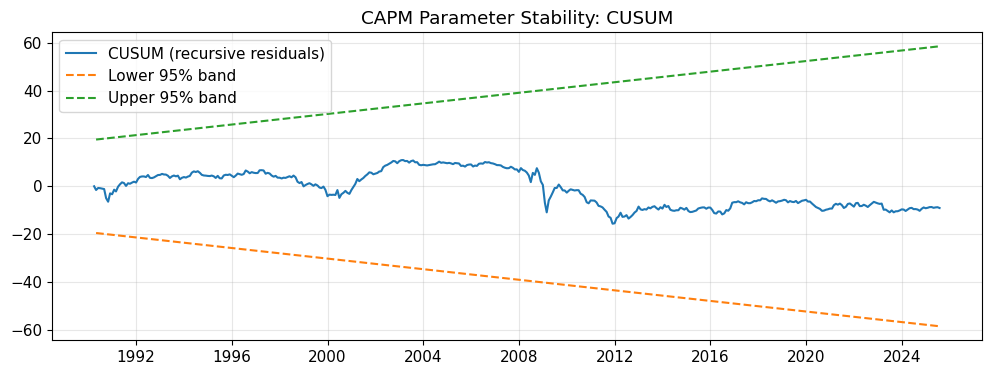

In [ ]:
# Make sure X already includes the constant
res_plain = sm.OLS(y, X).fit()

# This returns 7 objects (arrays); assign them to avoid printing everything
(rresid, rparams, ypred,
 rresid_std, rresid_scaled,
 rcusum, rcusum_ci) = recursive_olsresiduals(res_plain, alpha=0.95)

# If you want to sanity-check what you got, inspect shapes (one print total)
names  = ["rresid","rparams","ypred","rresid_std","rresid_scaled","rcusum","rcusum_ci"]
shapes = [np.asarray(a).shape for a in (rresid, rparams, ypred, rresid_std, rresid_scaled, rcusum, rcusum_ci)]


# Plot CUSUM with 95% bands
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(capm.index[1:], rcusum, lw=1.5, label="CUSUM (recursive residuals)")
ax.plot(capm.index[2:], rcusum_ci[0], ls="--", label="Lower 95% band")
ax.plot(capm.index[2:], rcusum_ci[1], ls="--", label="Upper 95% band")
ax.set_title("CAPM Parameter Stability: CUSUM")
ax.legend(); plt.show()


**Rolling $\beta_t$ for timing and magnitude**

CUSUM/CUSUMSQ answer **“is the relation stable?”** A rolling slope answers **“when and by how much did it move?”** Using a 60-month window,

$$
\hat{\beta}_t
=\frac{\operatorname{Cov}_{t-59:t}\!\bigl(R^{e}_{i},R^{e}_{m}\bigr)}
{\operatorname{Var}_{t-59:t}\!\bigl(R^{e}_{m}\bigr)}.
$$

Interpret persistent shifts as **regime changes** in systematic exposure; short-lived swings are **transient**.

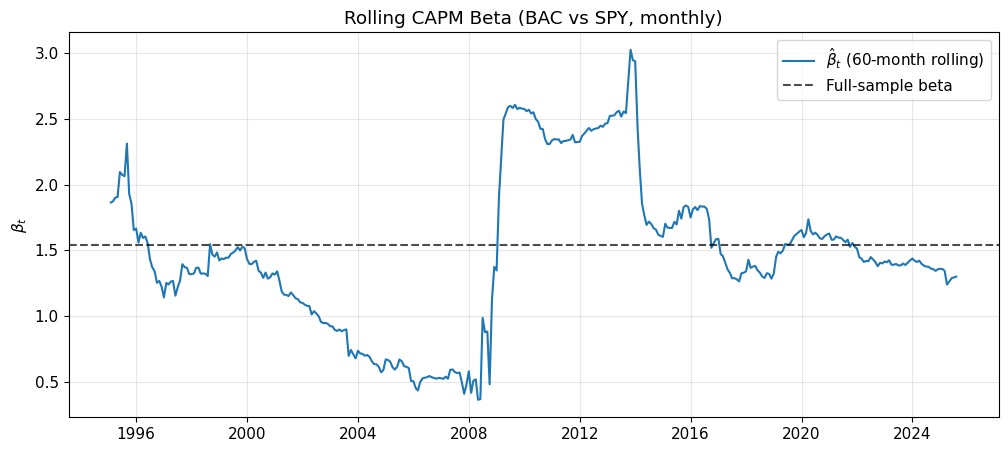

In [ ]:
# Rolling 60-month beta (closed-form slope), visualized

w = 60  # 5 years
rm_ex = capm["rm_ex"]
ri_ex = capm["ri_ex"]

beta_roll = rm_ex.rolling(w).cov(ri_ex) / rm_ex.rolling(w).var()
beta_roll = beta_roll.dropna()

fig, ax = plt.subplots()
ax.plot(beta_roll.index, beta_roll, lw=1.5, label=r"$\hat{\beta}_t$ (60-month rolling)")
ax.axhline(beta, color="k", ls="--", alpha=0.7, label="Full-sample beta")
ax.set_title("Rolling CAPM Beta (BAC vs SPY, monthly)")
ax.set_ylabel(r"$\beta_t$")
ax.legend()
plt.show()


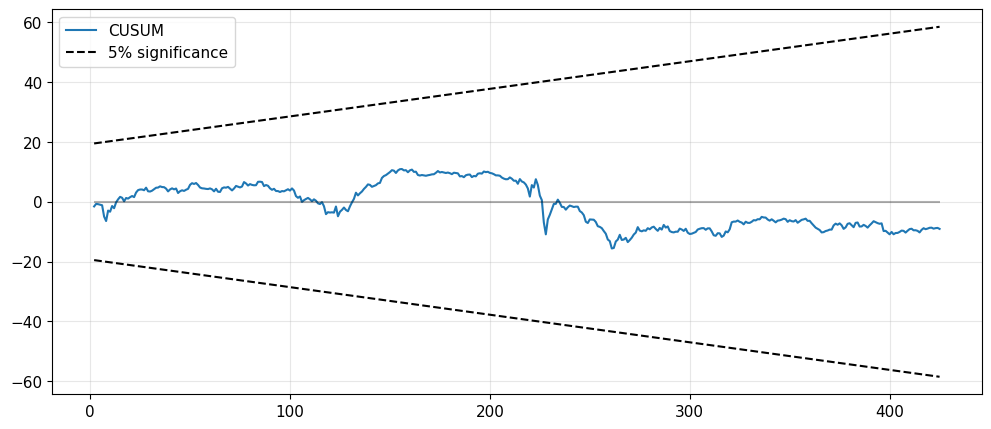

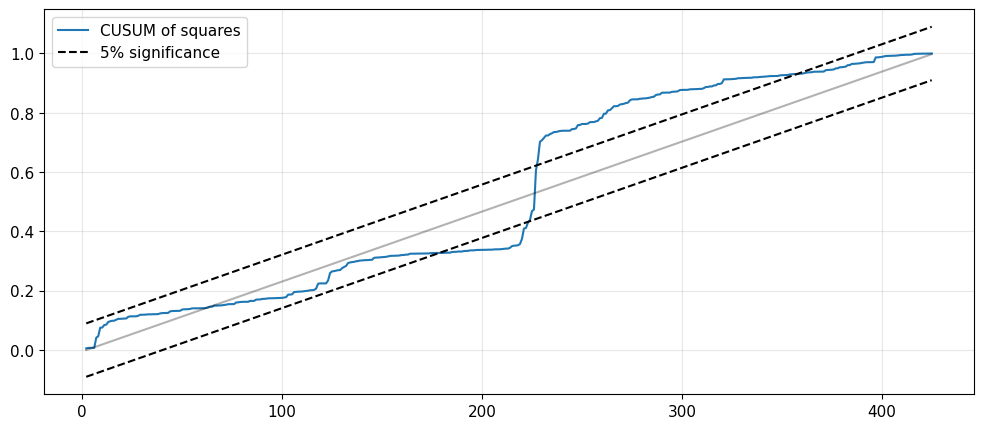

In [ ]:
# CUSUM and CUSUMSQ via RecursiveLS (handles indexing/bands internally)
mod_rls = sm.RecursiveLS(y, X)  # X includes the constant
res_rls = mod_rls.fit()

res_rls.plot_cusum()
plt.show()

res_rls.plot_cusum_squares()
plt.show()


The two figures summarize whether the CAPM relation

$$
R^{e}_{i,t}=\alpha+\beta\,R^{e}_{m,t}+\varepsilon_t
$$

is stable through time when estimated recursively. The **CUSUM** plot traces

$$
\text{CUSUM}(t)=\sum_{j=k+1}^{t}\frac{w_j}{\hat{\sigma}},
$$

where $w_t$ are recursive residuals and $k$ is the number of regressors (here $k=2$). Because the path remains **inside** the $5\%$ confidence bands, we **fail to reject** the null that the parameters $(\alpha,\beta)$ exhibit no systematic drift over the sample. This means that, in a global sense, the mean pricing relation does not display a persistent shift large enough to breach the widening boundaries implied by the Brownian–bridge reference distribution.

By contrast, the **CUSUM of squares** plot traces

$$
\text{CUSUMSQ}(t)=\sum_{j=k+1}^{t}\frac{w_j^{2}}{\sum_{j=k+1}^{T}w_j^{2}},
$$

and its path **exits** the $5\%$ bands. This leads us to **reject** stability for the squared recursive residuals, which is diagnostic of **variance instability** (heteroskedasticity and volatility regimes) in the regression errors rather than a clean, monotone drift in $(\alpha,\beta)$. The economic reading is that the exposure of a bank stock to the market can be estimated around a roughly constant central relation, yet the **uncertainty around that relation** changes markedly across market regimes (e.g., crisis windows), concentrating a disproportionate share of residual variance in specific periods.

This pair of tests delivers a key lesson about model failure: **absence of CUSUM breach does not imply full stability**. CUSUM primarily detects level shifts in parameters, while CUSUMSQ is sensitive to **scale changes** in the error process. Together with HAC standard errors and the rolling estimate $\hat{\beta}_t$, the notebook teaches a coherent workflow: use CUSUM to assess global drift in $(\alpha,\beta)$, use CUSUMSQ to diagnose volatility–regime effects in $\varepsilon_t$, and use $\hat{\beta}_t$ to time and size economically meaningful episodes.


### **3.2 Adaptation Strategies That Don't Backfire**

When regime shifts are detected, the temptation is to retrain models on recent data immediately. This is like learning to drive by studying only yesterday's traffic patterns – you might overfit to temporary conditions while forgetting enduring principles. Yet persisting with obsolete models guarantees poor performance.

The solution often lies in ensemble approaches that blend models trained on different time periods or market conditions. Each model captures particular regime characteristics, while the ensemble adapts to changing conditions through dynamic weighting. The weights themselves become parameters requiring optimization (but how do we optimize them without falling into the same overfitting trap?).

It pays to consider model uncertainty explicitly during regime transitions. Bayesian model averaging provides a principled framework for combining predictions from multiple candidate models, with weights reflecting each model's posterior probability given observed data. As new evidence accumulates, the weights naturally shift toward models better explaining current conditions.

## **4. Post-Mortem Analysis of Model Failures**

### **4.1 Forensic Finance: Dissecting the Corpse**

When models fail catastrophically, conducting thorough autopsies prevents future deaths. The analysis must penetrate beyond surface symptoms to understand root causes and why existing safeguards failed to prevent disaster. This is like investigating a plane crash – every component, procedure, and decision requires scrutiny.

The Zillow house-flipping debacle offers an instructive case study in algorithmic hubris. Zillow believed their data advantage – listing prices, search traffic, user behavior, proprietary Zestimate valuations – would enable profitable algorithmic real estate speculation. They were wrong in ways that would make a statistics textbook blush.

A bit more precisely, their model failed along multiple dimensions simultaneously:
- **Reflexivity**: Their aggressive buying influenced the very prices they predicted (why didn't they account for this feedback effect?)
- **Correlation risk**: Purchases clustered geographically, violating diversification assumptions
- **Liquidity risk**: Holding periods exceeded model assumptions during market downturns  
- **Reputational effects**: Market sentiment turned against perceived price manipulation

The post-mortem revealed that models ignoring their own market impact, assuming infinite liquidity, or overlooking behavioral responses to their actions are destined for failure when deployed at scale. Note that these weren't technical modeling errors but flawed assumptions about market structure and participant behavior.

### **4.2 The Subprime Mortgage Crisis: When Everyone Is Wrong Together**

The 2008 subprime mortgage crisis represents perhaps the most studied example of systemic model failure. Rating agencies' models, shrouded in proprietary secrecy, systematically underestimated mortgage default correlations while overestimating the value of complex structured products built on those mortgages.

The failure cascade began with flawed assumptions about housing prices – that they couldn't decline nationally simultaneously (have you ever wondered why intelligent people believed this?). Models ignored origination quality deterioration as underwriting standards eroded. Conflicts of interest in the rating process created incentives to produce favorable ratings rather than accurate assessments.

It pays to understand that model complexity isn't automatically beneficial. Complex models with numerous parameters and opaque relationships can hide fundamental flaws that simpler, more transparent models would expose. The crisis highlighted how proprietary models prevent independent validation – when models are black boxes, market participants cannot assess their validity or identify shared weaknesses.

The systemic nature emerged because multiple institutions relied on similar flawed models, creating correlated failures across the financial system. Diversification disappeared precisely when it was needed most, like umbrellas that dissolve in rain.

## **5. Computational Methods: CUSUM and Change Point Detection**

### **5.1 The CUSUM Algorithm: Sequential Detective Work**

The Cumulative Sum algorithm treats change detection like a detective following clues – it accumulates evidence sequentially until reaching a verdict. Unlike traditional hypothesis testing that requires complete data collection before analysis, CUSUM operates online, making decisions as each observation arrives.

The algorithm maintains two running tallies: one detecting increases ($S^+$) and another detecting decreases ($S^-$) in the process mean. At time $t$:

$$S_t^+ = \max(0, S_{t-1}^+ + x_t - (\mu_0 + k))$$
$$S_t^- = \max(0, S_{t-1}^- - x_t + (\mu_0 - k))$$

where $x_t$ is the current observation, $\mu_0$ represents the target mean, and $k$ denotes the reference value (typically half the shift magnitude we wish to detect). An alarm sounds when either sum exceeds threshold $h$, chosen to achieve desired false alarm rates.

For model monitoring, we apply CUSUM to prediction errors, log-likelihood scores, or performance metrics (but why do we need two separate statistics rather than one?). The sequential nature enables rapid degradation detection while maintaining statistical rigor. The key advantage over simple moving averages is CUSUM's memory – small persistent shifts accumulate over time, eventually triggering detection even when individual observations remain within normal bounds.

### **5.2 Advanced Change Point Detection: Beyond CUSUM**

A bit more precisely, modern change point detection employs algorithms capable of identifying multiple breakpoints, variance changes, and multivariate distribution shifts. The PELT (Pruned Exact Linear Time) algorithm efficiently locates multiple change points by minimizing a penalized cost function.

For observation sequence $y_{1:n}$, we minimize:
$$\sum_{i=1}^{m+1} \mathcal{C}(y_{t_{i-1}:t_i}) + \beta m$$

where $m$ represents the change point count, $t_i$ denote change point locations, $\mathcal{C}$ is the segment cost function (typically negative log-likelihood), and $\beta$ controls the penalty for model complexity.

Note that financial applications often require detecting correlation structure changes or volatility regime shifts. Dynamic Conditional Correlation models with regime-switching components can identify when correlation matrices undergo structural breaks – critical for risk models assuming stable dependence structures.

## **6. Case Studies of Notable Model Failures**

### **6.1 Long-Term Capital Management: When Genius Goes Bust**

LTCM's 1998 collapse reads like a Greek tragedy starring Nobel laureates. Their models, crafted by academic titans, assumed historical relationships between securities would persist and markets would remain liquid enough to maintain positions until convergence occurred. They were wrong on both counts, spectacularly.

The models failed to account for one crucial possibility: multiple sophisticated investors holding similar positions, creating crowded trades that would unwind simultaneously during market stress (why didn't they consider this correlation risk?). When Russia defaulted on its debt, triggering global flight-to-quality, spreads that "had to" converge instead widened dramatically. Liquidity evaporated precisely when needed most.

LTCM's leverage transformed model errors into existential threats not just to the fund but to the broader financial system. The assumption of market completeness and continuous trading proved catastrophically incorrect during precisely the conditions when the model was most needed. It pays to remember that models work best during normal times when you need them least.

### **6.2 The Quant Quake of August 2007: When Everyone Drowns Together**

The August 2007 "Quant Quake" demonstrated how similar models across different institutions can create systemic instabilities. During one infamous week, numerous quantitative equity funds experienced simultaneous severe losses despite no obvious market catalyst – like synchronized swimmers all forgetting the routine simultaneously.

Post-mortem analysis revealed that many funds ran similar factor models, creating crowded positions in identical securities. When one large fund liquidated positions to meet redemptions, prices moved against all funds holding similar positions, triggering further selling and creating vicious feedback loops (have you considered how model similarity can eliminate diversification benefits?). Models showing excellent backtested performance and low correlation suddenly became highly correlated during crisis.

The episode highlighted how model risk becomes systemic when many participants employ similar approaches, even with different specific implementations. Diversification disappeared when needed most, like emergency exits that all lead to the same blocked corridor.

### **6.3 Machine Learning Overfitting: The Memorization Trap**

Modern machine learning models introduce novel failure modes, particularly overfitting – where models memorize noise in training data rather than learning genuine patterns. This resembles students who excel at practice exams by memorizing specific questions but fail when tested on new material.

Consider polynomial regression's progression from simplicity to complexity. As model sophistication increases, training error decreases monotonically while test error typically follows a U-shaped curve – initially decreasing as genuine patterns are captured, then increasing as noise becomes memorized. The optimal complexity depends on signal-to-noise ratio and training data availability (but how do we determine this optimum prospectively?).

For financial applications, overfitting proves particularly dangerous because market relationships are non-stationary. A model perfectly capturing historical patterns may perform worse than random guessing if those patterns no longer hold. Regularization techniques, cross-validation, and ensemble methods mitigate overfitting but cannot eliminate the fundamental challenge of learning from limited, noisy, evolving data.

## **7. Model Governance Best Practices**

### **7.1 Documentation: The Boring Stuff That Saves You**

Effective model governance begins with comprehensive documentation – the equivalent of a detailed medical chart that enables proper diagnosis when things go wrong. Every model requires documentation covering theoretical foundation, assumptions, limitations, and appropriate use cases. This isn't bureaucratic box-checking but intellectual discipline that forces clarity of thought.

Models should undergo independent validation before deployment, like peer review for academic papers. Validators must test statistical performance, logical consistency, stability across market conditions, and sensitivity to input perturbations (why is independence crucial here?). The validation process should specifically probe behavior at extremes where failures typically originate.

A bit more precisely, documentation standards should include:
- **Model purpose and scope**: What problem does it solve and where should it be applied?
- **Theoretical foundation**: What assumptions underpin the model's construction?
- **Data requirements**: What inputs are needed and what quality standards apply?
- **Performance benchmarks**: How should success be measured?
- **Known limitations**: Where does the model break down?
- **Sensitivity analysis**: How robust are predictions to input changes?

Version control and change management prevent unauthorized modifications from introducing unexpected behaviors. Emergency override procedures should exist for obvious model malfunctions, but overrides themselves require documentation and review to prevent abuse.

### **7.2 Continuous Monitoring: Eternal Vigilance**

Model governance doesn't end at deployment any more than parenting ends when children leave home. Continuous monitoring systems must track performance while comparing realized outcomes against expectations. These systems need clear escalation procedures specifying who receives notifications when performance degrades, what actions they should take, and response timeframes.

Periodic reviews should reassess whether models remain fit for purpose as markets evolve, regulations change, and new data becomes available. A model developed for one market regime may become obsolete in another. These reviews should be scheduled events rather than performance-triggered reactions – by the time performance visibly degrades, significant losses may have already occurred.

Note that review processes must examine not just individual models but also model interactions and dependencies. In complex organizations, models often feed into each other, creating chains where upstream failures cascade through entire systems (have you mapped these dependencies in your organization?). Understanding interdependencies and implementing circuit breakers prevents localized failures from becoming systemic disasters.

### **7.3 Culture: The Soft Stuff That's Actually Hard**

The best technical standards prove worthless without organizational culture valuing model integrity over short-term performance. Incentive structures should reward those identifying model weaknesses rather than punishing messengers highlighting problems. The "shoot the messenger" syndrome has contributed to numerous model-related disasters throughout financial history.

Model developers and users require appropriate training to understand both capabilities and limitations. The dangerous middle ground involves knowing enough to use models but not enough to recognize failure. This is like giving someone car keys without teaching them traffic rules.

It pays to cultivate healthy model skepticism throughout the organization. Models are tools, not oracles – they inform judgment but don't replace it. When model outputs violate common sense or market intuition, discrepancies deserve investigation. Sometimes models reveal non-obvious truths, but often they signal impending failure.

## **8. Conclusion**

Model failure analysis represents essential competency for financial engineers navigating increasingly complex markets. Models fail for three fundamental reasons: incorrect specification, incorrect usage, or inappropriate application outside their validity domain. Understanding these failure modes while implementing robust detection, monitoring, and governance frameworks significantly reduces model risk.

The early warning indicators we've explored – from statistical deviations to logical violations – provide the first line of defense against model breakdown. Statistical process control enables continuous monitoring that detects degradation before causing significant losses (though financial markets mock manufacturing analogies). Understanding regime shifts helps recognize when models need fundamental revision rather than mere parameter adjustment.

Our case studies from LTCM to Zillow demonstrate that model failure affects even sophisticated participants using cutting-edge techniques. These failures often stem not from technical deficiencies but from flawed assumptions about market behavior, inadequate consideration of reflexivity and feedback effects, or simple hubris about model capabilities.

Note that computational methods like CUSUM and change point detection provide practical implementation tools. Yet tools alone prove insufficient – they must be embedded within comprehensive governance frameworks promoting model transparency, independent validation, and continuous improvement.

Moving forward, financial engineers must balance sophistication with interpretability, statistical rigor with practical judgment, and innovation with prudent risk management. Models will continue failing – markets are too complex and dynamic for perfect prediction. But by understanding failure modes, implementing robust monitoring, and learning from past mistakes, we can build more resilient modeling frameworks that fail gracefully rather than catastrophically.

A final thought: the best model is often the one that knows its own limitations.

**References**

* Emanuel Derman and Paul Wilmott. *The Financial Modelers' Manifesto*. January 7, 2009.
* MacKenzie, Donald. *An Engine, Not a Camera: How Financial Models Shape Markets*. MIT Press, 2006.

---
Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.